# 3. Cell annotation

This tutorial assigns reference-based cell types to previously computed `CellEmbeddings`.

> **This tutorial teaches**
>
> - **Task:** annotate image-derived cells with cell types
> - **Required inputs:** `CellEmbeddings` and a single-cell reference
> - **Output:** `AnnotationResult`
> - **Example used here:** the cells saved in Tutorial 2 and the prebuilt breast reference
> - **Key concept:** retrieval in the shared cell space and annotation confidence

```text
CellEmbeddings + reference  →  annotate()  →  AnnotationResult
```

Because the cells have already been encoded, this workflow does not run the H&E image encoder
again.

> **Example outputs.** The outputs shown in this tutorial annotate the cells of Tutorial 2, from the
> H&E image of the 10x Genomics *FFPE Human Breast with Custom Add-on Panel* dataset, with the
> prebuilt Breast reference.
>
> Source: [FFPE Human Breast with Custom Add-on Panel](https://www.10xgenomics.com/datasets/ffpe-human-breast-with-custom-add-on-panel-1-standard), 10x Genomics,
> [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). The image is cropped and overlaid with
> ALHENA predictions.

In [1]:
from pathlib import Path

import numpy as np

import alhena
from alhena import io

# The cells Tutorial 2 saved.
CELLS = Path("alhena_out/cells.h5ad")

# Tissue used to select a prebuilt reference.
TISSUE = "Breast"

# Optional custom or local reference file.
# Leave as None to use the prebuilt reference for TISSUE.
REFERENCE = None

OUT = Path("alhena_out")

print(alhena.__version__)

0.1.0


## Load the reference and inspect class support

`available_tissues()` lists the tissues with prebuilt references. Choose a tissue, then use
`load_celltyper()` to load its reference and inspect the classes it supports. A reference can only
predict classes represented in its retrieval pool.

`missing_classes` names classes with no reference cells; `thin_classes` names classes with
relatively limited support. See [Check class support](../../inputs/references/#check-class-support).

In [2]:
print("tissues with a prebuilt reference:", ", ".join(alhena.available_tissues()))

typer = alhena.load_celltyper(tissue=None if REFERENCE else TISSUE, reference=REFERENCE)
info = typer.reference.info

print(typer.axis, typer.class_order)
print(info.name, "|", info.n_scored_cells, "reference cells in the retrieval pool")
pool = sum(info.class_support.values())
print(f"  {'class':<24} {'cells':>8}  % of the retrieval pool")
for name, support in info.class_support.items():
    print(f"  {name:<24} {support:>8}  {support / pool:.1%}")
print("cannot express:", info.missing_classes)
print("thinly supported:", info.thin_classes)

tissues with a prebuilt reference: BoneMarrow, Breast, Cervix, Colon, Heart, Kidney, Liver, Lung, LymphNode, Ovary, Pancreas, Prostate, Skin, Tonsil, Uterus


lineage_v1 ('B_Plasma', 'Epithelial_Melanocyte', 'Myeloid', 'Stromal_Vascular', 'T_NK')
breast | 172831 reference cells in the retrieval pool
  class                       cells  % of the retrieval pool
  B_Plasma                      523  0.3%
  Epithelial_Melanocyte      116220  67.2%
  Myeloid                      2735  1.6%
  Stromal_Vascular            49160  28.4%
  T_NK                         4193  2.4%
cannot express: ()
thinly supported: ()


## Annotate the saved cells

`read_cells()` restores the `CellEmbeddings` and their provenance. `annotate()` then compares the
projected cell representations with the selected single-cell reference.

For each query cell, retrieved reference neighbors contribute a similarity-weighted vote and the
class with the largest mass is selected.

Because the H&E cells are already encoded, no image tiles are processed in this step.

To encode and annotate in one step, use `annotate()`: it takes image tiles and nuclei directly, and
then encodes and annotates them in one call, as [Tutorial 6](../06_annotation_evaluation/) does.

In [3]:
cells = io.read_cells(CELLS)
result = typer.annotate(cells)

print(len(result), "cells annotated on", result.axis)
print("encoder loaded:", typer.encoder is not None)

36804 cells annotated on lineage_v1
encoder loaded: False


## Inspect the annotations

`to_frame()` returns one row per cell with the predicted label, confidence, validity flag, and
class-mass values, followed by the position and tile of each cell.

- **Confidence** is the fraction of the weighted reference vote assigned to the winning class. It
  is not the probability that the prediction is correct.
- **`valid`** indicates whether an annotation was assigned. Invalid rows remain present with an
  empty label.

See [Cell annotations](../../outputs/cell-annotations/) for the complete result format.

In [4]:
frame = result.to_frame()

print("annotated", int(result.valid.sum()), "of", len(result))
confidence = result.confidence[result.valid]
print(f"confidence below 0.9: {np.mean(confidence < 0.9):.1%} of annotated cells")
print(frame.loc[frame["valid"], "label"].value_counts())
frame[["cell_id", "label", "confidence", "valid", "x", "y"]].head()

annotated 36804 of 36804
confidence below 0.9: 8.3% of annotated cells
label
Epithelial_Melanocyte    21853
Stromal_Vascular         13305
Myeloid                    988
T_NK                       506
B_Plasma                   152
Name: count, dtype: int64


,cell_id,label,confidence,valid,x,y
0,ablknega-1,Epithelial_Melanocyte,1.0,True,31036.501304,40334.045199
1,abllcdad-1,Epithelial_Melanocyte,1.0,True,31039.843747,40382.456599
2,ablljpoe-1,Epithelial_Melanocyte,1.0,True,31070.121026,40384.777115
3,abllmagm-1,Epithelial_Melanocyte,1.0,True,31085.296591,40423.721863
4,abllobgk-1,Epithelial_Melanocyte,1.0,True,31022.185449,40432.704476


### Look inside a less confident annotation

Confidence summarizes how strongly the retrieved reference cells agree on the winning class. To see
what a less decisive vote looks like, inspect the class masses for a few cells with the lowest
confidence.

The masses show how the vote is distributed across possible classes; they are not calibrated
probabilities of correctness. A high-confidence annotation can still be wrong, so evaluating
confidence against known labels is a separate task in [Tutorial 6](../06_annotation_evaluation/).

In [5]:
# One column per cell: its label, its confidence and its class masses.
masses = [column for column in frame.columns if column.startswith("mass_")]
lowest = frame[frame["valid"]].nsmallest(3, "confidence").set_index("cell_id")
lowest[["label", "confidence", *masses]].round(3).T

cell_id,ebnakilg-1,afnmcohb-1,dabhllcf-1
label,Myeloid,T_NK,Myeloid
confidence,0.311,0.318,0.324
mass_B_Plasma,0.127,0.31,0.137
mass_Epithelial_Melanocyte,0.038,0.138,0.087
mass_Myeloid,0.311,0.0,0.324
mass_Stromal_Vascular,0.296,0.234,0.165
mass_T_NK,0.229,0.318,0.286


## Cell embeddings used for annotation

`result.cells` contains the `CellEmbeddings` used to produce the annotations in exactly the same
row order. The image-derived embedding, spatial position, and annotation for a cell can therefore
be accessed without an additional join.

In [6]:
print("same order:", bool((result.cells.cell_id == result.cell_id).all()))

same order: True


## Annotate the same cells on another axis

Cell encoding is independent of the reference and annotation axis. The same `CellEmbeddings` can
therefore be annotated again without another image-encoder pass.

Here, the same cells are annotated using the broader `compartment_v1` axis. Performance or
composition summaries from different axes should be interpreted separately because they represent
different classification problems.

See [The class axis](../../inputs/references/#the-class-axis).

In [7]:
compartments = alhena.load_celltyper(
    tissue=None if REFERENCE else TISSUE, reference=REFERENCE, axis="compartment_v1"
)
coarse = compartments.annotate(cells)

print(coarse.axis, coarse.class_order)
print(coarse.to_frame().loc[coarse.valid, "label"].value_counts())

compartment_v1 ('Epithelial_Melanocyte', 'Immune', 'Stromal_Vascular')
label
Epithelial_Melanocyte    21853
Stromal_Vascular         13294
Immune                    1657
Name: count, dtype: int64


## Visualize cell-type composition and spatial distribution

The `viz` utilities can summarize the fraction of cells assigned to each class and display the
annotated cells at their spatial positions. Classes that are absent from the selected reference can
also be indicated explicitly.

Plotting requires the `viz` extra.

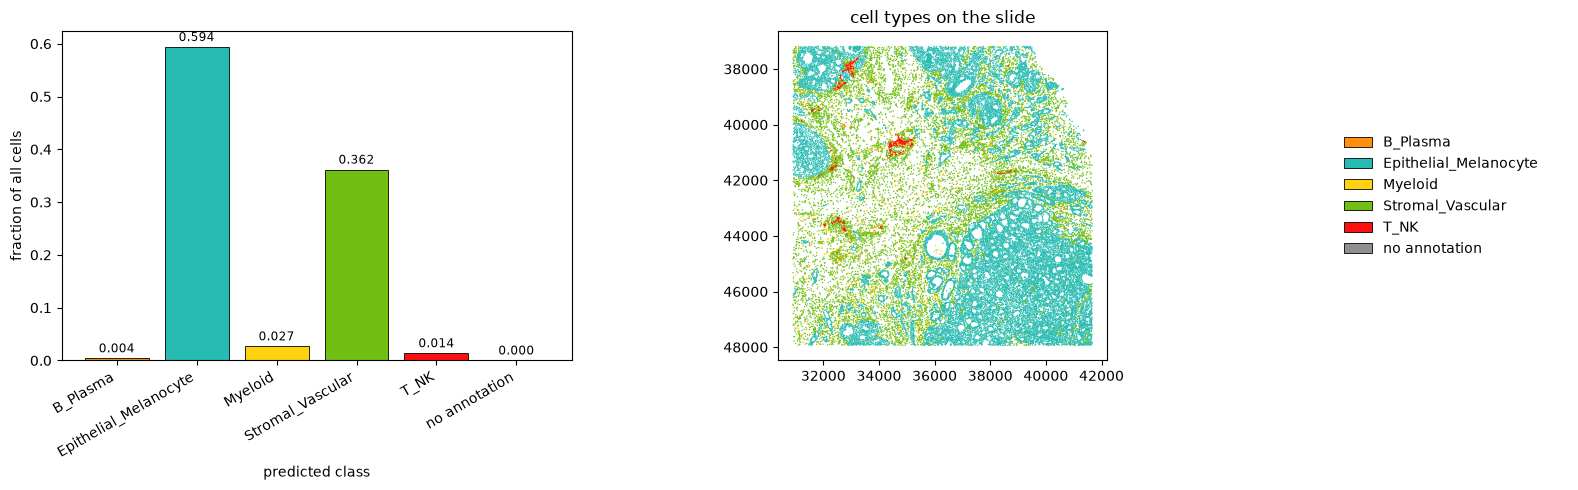

In [8]:
import matplotlib.pyplot as plt

from alhena import viz

figure, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [2, 3, 1]})
viz.composition(result, ax=axes[0], missing_classes=typer.reference)

called = result.valid
x, y = result.cells.centroids[called].T
axes[1].scatter(x, y, c=[viz.class_color(name) for name in result.labels[called]], s=1, linewidths=0)
axes[1].invert_yaxis()          # image rows run downward
axes[1].set_aspect("equal")
axes[1].set_title("cell types on the slide")

viz.legend(typer.axis, ax=axes[2], missing_classes=typer.reference)
figure.tight_layout()

### See the annotations on H&E

The composition plot summarizes the predictions, but it does not show which nuclei received each
label on the tissue image. `viz.overlay()` colors segmented nuclei by their predicted class while
leaving the H&E image visible.

The saved cells record the identifier and the position of each nucleus. The outlines stay in
`nuclei.geojson`, the file Tutorial 2 read them from. To draw the cells, read one tile of the slide
and the outlines on it. `viz.overlay()` matches each outline to its annotation by cell identifier,
so the colors are those of the annotations above, and no image is encoded again.

In [9]:
# One tile of the region of Tutorial 2, by its top-left corner, and the outlines on it.
SLIDE = Path("slide.ome.tif")
NUCLEI = Path("nuclei.geojson")
TILE = np.array([[32704, 38080]])

tile = io.read_slide(SLIDE, coords=TILE)
outlines = io.read_polygons(NUCLEI, tiles=tile)

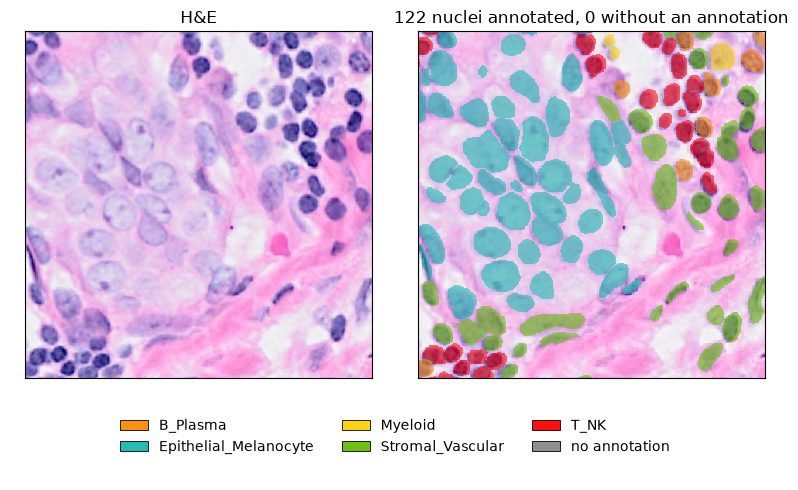

In [10]:
figure, axes = plt.subplot_mosaic(
    [["he", "overlay"], ["legend", "legend"]], figsize=(8, 5), height_ratios=[4, 1]
)
axes["he"].imshow(tile[0])
axes["he"].set(title="H&E", xticks=[], yticks=[])
viz.overlay(tile[0], outlines, result, ax=axes["overlay"])
viz.legend(typer.axis, ax=axes["legend"], missing_classes=typer.reference, ncols=3)
figure.tight_layout()

Each colored region corresponds to a segmented nucleus. The class colors identify ALHENA's
predictions, not independently verified cell types. This view helps connect the annotation table to
the tissue morphology; it does not measure annotation accuracy.

## Save the result

One table holds the cells, their embeddings and provenance, and both annotations. `to_anndata()`
returns the table with the `lineage_v1` annotation, and `io.add_annotation()` adds the
`compartment_v1` annotation beside it. The columns of each annotation are named after its axis,
such as `alhena_celltype_lineage_v1`. `write_h5ad()` saves the table, so the cells and their
annotations can be reused later: `io.read_annotations()` reads an annotation back with its cells,
as Tutorial 4 does.

A CSV export of `to_frame()` stores only the annotation table.

See [Persistence and interchange](../../outputs/persistence/).

In [11]:
table = result.to_anndata()
io.add_annotation(table, coarse)
print([column for column in table.obs.columns if column.startswith("alhena_celltype")])

table.write_h5ad(OUT / "annotations.h5ad")
frame.to_csv(OUT / "cell_types.csv", index=False)

['alhena_celltype_lineage_v1', 'alhena_celltype_compartment_v1']


## How can the annotations be evaluated?

The predictions above did not require labeled H&E cells. When independently labeled nuclei are
available, ALHENA can compare predicted and known classes, show where they disagree, and examine
what happens when only more confident predictions are retained.

[Tutorial 6](../06_annotation_evaluation/) demonstrates this separate evaluation workflow,
including a confusion matrix and confidence curves. No accuracy claim can be inferred from the
composition or overlay shown here.

## Where next

Tile embeddings, cell embeddings, and cell-type annotations can now be analyzed together in
[Tutorial 4](../04_multiscale_analysis/).

---

**Next:** [4. Multi-scale slide analysis](../04_multiscale_analysis/)